# Person 3 - Lifestyle habits (SMQ, ALQ, PAQ, SLQ, DBQ)

Run top to bottom from anywhere inside the repo (needs `data/raw/nhanes/<cycle>/` for the code map and
`data/interim/merged_<cycle>.csv` or `people_<cycle>.csv` for the risk charts).

Sections: 1 setup - 2 decision log - 3 code map - 4 conversion tables - 5 build both cycles and compare - 6 EDA charts.
The final logic lives in `src/data/lifestyle.py`; this notebook shows the thinking and the evidence.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import lifestyle as L

CYCLES = ["2017-2018", "2021-2023"]
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 200, "display.width", 140)

# one ink family, one data colour (single series -> no legend; the title names it)
INK, MUTED, GRID, BLUE = "#1f2937", "#6b7280", "#e5e7eb", "#2a6fdb"
plt.rcParams.update({
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 110,
})
plt.rcParams["axes.grid.axis"] = "y"

## 1. Raw loaders used for the evidence below

In [2]:
def read_unfixed(cycle, stem):
    # raw file exactly as stored (5.4e-79 zeros NOT yet fixed), indexed by SEQN
    path = L._find_raw_file(L.RAW_DIR, cycle, stem)
    df = pd.read_csv(path) if path.suffix.lower() == ".csv" else pd.read_sas(path, format="xport")
    df.columns = [c.upper() for c in df.columns]
    return df.set_index("SEQN")

def available(cycle):
    try:
        return {s: read_unfixed(cycle, s) for s in L.STEMS}
    except FileNotFoundError as e:
        print(f"[{cycle}] raw files not found: {e}")
        return None

RAW = {c: available(c) for c in CYCLES}
{c: (None if v is None else {k: len(t) for k, t in v.items()}) for c, v in RAW.items()}

{'2017-2018': {'SMQ': 6724,
  'ALQ': 5533,
  'PAQ': 5856,
  'SLQ': 6161,
  'DBQ': 9254},
 '2021-2023': {'SMQ': 9015,
  'ALQ': 6337,
  'PAQ': 8153,
  'SLQ': 8501,
  'DBQ': 11933}}

## 2. Decision log

One row per change to the data. `rows 17-18` / `rows 21-23` are counted live from the raw files, so the table is
evidence, not opinion. Decisions 11 and 14-16 are the ones the handbook asks me to fill in myself.

In [3]:
def counts(cycle):
    t = RAW[cycle]
    if t is None:
        return {}
    smq, alq, paq, slq, dbq = (t[s] for s in L.STEMS)
    num = lambda df, c: L._num(df, c)
    tiny = 0
    for df in t.values():
        for c in df.columns:
            if pd.api.types.is_numeric_dtype(df[c]):
                a = df[c].abs()
                tiny += int(((a < L.FAKE_TINY) & (a > 0)).sum())
    out = {
        1: tiny,
        2: int(num(smq, "SMQ020").isin([7, 9]).sum() + num(smq, "SMQ040").isin([7, 9]).sum()),
        3: int((num(smq, "SMQ020") == 2).sum()),
        4: int((num(alq, "ALQ111") == 2).sum()),
        5: int(num(alq, "ALQ121").isin(list(L.ALQ121_DAYS_PER_YEAR)).sum()),
        6: int(num(alq, "ALQ121").isin([77, 99]).sum() + num(alq, "ALQ130").isin([777, 999]).sum()),
        7: int((num(alq, "ALQ121").abs() < L.FAKE_TINY).sum()),
        13: int(num(paq, "PAD680").isin([7777, 9999]).sum()),
        15: int(num(dbq, "DBQ700").isin([7, 9]).sum()),
    }
    if cycle == "2017-2018":
        out[8] = int(((num(paq, "PAQ650") == 2) | (num(paq, "PAQ665") == 2)).sum())
        out[9] = int(sum(num(paq, c).isin(codes).sum() for c, codes in [
            ("PAQ650", [7, 9]), ("PAQ665", [7, 9]), ("PAQ655", [77, 99]), ("PAQ670", [77, 99]),
            ("PAD660", [7777, 9999]), ("PAD675", [7777, 9999])]))
    else:
        out[8] = int(((num(paq, "PAD790Q").abs() < L.FAKE_TINY) | (num(paq, "PAD810Q").abs() < L.FAKE_TINY)).sum())
        out[9] = int(sum(num(paq, c).isin([7777, 9999, 77777, 99999]).sum()
                         for c in ["PAD790Q", "PAD800", "PAD810Q", "PAD820"]))
        out[12] = int(paq["PAD790U"].notna().sum() + paq["PAD810U"].notna().sum())
    total = L.ACTIVITY_PATH[cycle](paq)
    out[11] = int((total > L.CAP_MIN_WEEK).sum())
    out[14] = int((num(slq, "SLD012").notna() & num(slq, "SLD013").notna()).sum())
    return out

C17, C21 = counts("2017-2018"), counts("2021-2023")

LOG = [
 (1, "all numeric", "zeros stored as 5.4e-79", "set |x| < 1e-6 to 0", "== 0 comparisons fail, tiny values look real"),
 (2, "SMQ020, SMQ040", "7 / 9 = refused / don't know", "set to NaN", "codes, not answers"),
 (3, "SMQ040", "blank when SMQ020 = 2 (skip pattern)", "SMQ020 = 2 -> never", "never-smokers are not asked 'do you smoke now'"),
 (4, "ALQ111", "ALQ111 = 2 (never had a drink) skips the rest", "drinks_week = 0", "gate question 'no' means 0, not unknown"),
 (5, "ALQ121", "frequency category 0-10, not a count", "days/year = midpoint of range, x ALQ130 / 52", "averaging codes would be meaningless (see table 4a)"),
 (6, "ALQ121, ALQ130", "77/99 and 777/999 = refused / don't know", "set to NaN", "codes, not values"),
 (7, "ALQ121", "0 = no drinking in the last 12 months (ALQ130 blank)", "drinks_week = 0", "skip pattern"),
 (8, "PAQ gates", "'no' -> days and minutes blank (2017); count 0 -> unit and minutes blank (2021)", "minutes = 0", "blank means 0 here, not unknown"),
 (9, "PAQ days / minutes", "7/9, 77/99, 7777/9999 codes", "set to NaN; total is NaN if any part unknown", "do not guess a missing part"),
 (10, "exercise_min_week", "vigorous vs moderate", "vigorous counts double", "WHO: 1 vigorous min ~ 2 moderate"),
 (11, "exercise_min_week", "impossible / extreme totals", f"cap at {L.CAP_MIN_WEEK:.0f} min/week (50 h)", "keeps the person, removes absurd leverage"),
 (12, "PAD790U, PAD810U", "units are bytes (b'W'), empty when count = 0", "decode; D/W/M/Y -> x7, x1, x12/52, x1/52", "same output as 2017 (table 4b)"),
 (13, "PAD680", "real values up to 1320 mixed with 7777 / 9999", "codes -> NaN", "codes would be averaged as minutes"),
 (14, "sleep_hours", "two columns (workday, weekend), both in both cycles", "(5 x SLD012 + 2 x SLD013) / 7; fall back to whichever exists", "weights a real week"),
 (15, "diet_quality", "DBQ700 only in 2017-2018; 7/9 codes", "codes -> NaN; empty in 2021-2023", "EDA / app tips only, NOT a model feature"),
 (16, "validation", "missing-% limit", "40% default; 100% allowed for diet_quality in 2021-2023", "set after looking at real missingness - revisit with real numbers"),
]
log = pd.DataFrame(LOG, columns=["#", "Column", "Problem found", "What I did", "Why"])
log["rows 17-18"] = log["#"].map(C17)
log["rows 21-23"] = log["#"].map(C21)
log.fillna("-")

,#,Column,Problem found,What I did,Why,rows 17-18,rows 21-23
0,1,all numeric,zeros stored as 5.4e-79,set |x| < 1e-6 to 0,"== 0 comparisons fail, tiny values look real",37666.0,15152.0
1,2,"SMQ020, SMQ040",7 / 9 = refused / don't know,set to NaN,"codes, not answers",0.0,14.0
2,3,SMQ040,blank when SMQ020 = 2 (skip pattern),SMQ020 = 2 -> never,never-smokers are not asked 'do you smoke now',3497.0,4878.0
3,4,ALQ111,ALQ111 = 2 (never had a drink) skips the rest,drinks_week = 0,"gate question 'no' means 0, not unknown",585.0,558.0
4,5,ALQ121,"frequency category 0-10, not a count","days/year = midpoint of range, x ALQ130 / 52",averaging codes would be meaningless (see tabl...,3492.0,4081.0
5,6,"ALQ121, ALQ130",77/99 and 777/999 = refused / don't know,set to NaN,"codes, not values",10.0,19.0
6,7,ALQ121,0 = no drinking in the last 12 months (ALQ130 ...,drinks_week = 0,skip pattern,1049.0,836.0
7,8,PAQ gates,'no' -> days and minutes blank (2017); count 0...,minutes = 0,"blank means 0 here, not unknown",4850.0,4514.0
8,9,PAQ days / minutes,"7/9, 77/99, 7777/9999 codes",set to NaN; total is NaN if any part unknown,do not guess a missing part,6.0,122.0
9,10,exercise_min_week,vigorous vs moderate,vigorous counts double,WHO: 1 vigorous min ~ 2 moderate,-,-


## 3. Code map

Every value in every coded column, with its count, for both cycles. Continuous columns show only the code values that
hide in them. The check at the end proves nothing is unexplained.

In [4]:
CODED = {  # categorical columns: list every value
    "SMQ": ["SMQ020", "SMQ040"],
    "ALQ": ["ALQ111", "ALQ121"],
    "PAQ": ["PAQ650", "PAQ655", "PAQ665", "PAQ670", "PAD790U", "PAD810U"],
    "DBQ": ["DBQ700"],
}
CONTINUOUS = {  # numeric columns: summary + the codes that hide in them
    "ALQ": {"ALQ130": [777, 999]},
    "PAQ": {"PAD660": [7777, 9999], "PAD675": [7777, 9999], "PAD680": [7777, 9999],
            "PAD790Q": [77777, 99999], "PAD800": [7777, 9999], "PAD810Q": [77777, 99999], "PAD820": [7777, 9999]},
    "SLQ": {"SLD012": [77, 99], "SLD013": [77, 99]},
}

def code_map(cycle):
    rows = []
    for stem, df in (RAW[cycle] or {}).items():
        for col in CODED.get(stem, []):
            if col in df:
                for value, n in df[col].map(lambda v: v.decode() if isinstance(v, bytes) else v).value_counts(dropna=False).sort_index().items():
                    rows.append((cycle, stem, col, value, n))
        for col, codes in CONTINUOUS.get(stem, {}).items():
            if col in df:
                s = pd.to_numeric(df[col], errors="coerce")
                rows.append((cycle, stem, col, f"real values {s[~s.isin(codes)].min():g}..{s[~s.isin(codes)].max():g}", int(s.notna().sum())))
                for code in codes:
                    if (s == code).any():
                        rows.append((cycle, stem, col, f"CODE {code}", int((s == code).sum())))
                rows.append((cycle, stem, col, "blank (skip pattern / not asked)", int(s.isna().sum())))
    return pd.DataFrame(rows, columns=["cycle", "file", "column", "value", "count"])

maps = pd.concat([code_map(c) for c in CYCLES], ignore_index=True)
maps

,cycle,file,column,value,count
0,2017-2018,SMQ,SMQ020,1.0,2359
1,2017-2018,SMQ,SMQ020,2.0,3497
2,2017-2018,SMQ,SMQ020,NaN,868
3,2017-2018,SMQ,SMQ040,1.0,805
4,2017-2018,SMQ,SMQ040,2.0,216
5,2017-2018,SMQ,SMQ040,3.0,1338
6,2017-2018,SMQ,SMQ040,NaN,4365
7,2017-2018,ALQ,ALQ111,1.0,4545
8,2017-2018,ALQ,ALQ111,2.0,585
9,2017-2018,ALQ,ALQ111,NaN,403


In [5]:
# differences between cycles: columns present in one cycle and not the other
for stem in L.STEMS:
    cols = {c: set(RAW[c][stem].columns) if RAW[c] else set() for c in CYCLES}
    if all(RAW[c] for c in CYCLES):
        print(stem, "only 2017-18:", sorted(cols["2017-2018"] - cols["2021-2023"]),
              "| only 2021-23:", sorted(cols["2021-2023"] - cols["2017-2018"]))

SMQ only 2017-18: ['SMD030', 'SMD057', 'SMD093', 'SMD100BR', 'SMD100CO', 'SMD100FL', 'SMD100LN', 'SMD100NI', 'SMD100TR', 'SMDUPCA', 'SMQ050Q', 'SMQ050U', 'SMQ078', 'SMQ661', 'SMQ665A', 'SMQ665B', 'SMQ665C', 'SMQ665D', 'SMQ670', 'SMQ848', 'SMQ852Q', 'SMQ852U', 'SMQ890', 'SMQ895', 'SMQ900', 'SMQ905', 'SMQ910', 'SMQ915'] | only 2021-23: []
ALQ only 2017-18: ['ALQ290'] | only 2021-23: []
PAQ only 2017-18: ['PAD615', 'PAD630', 'PAD645', 'PAD660', 'PAD675', 'PAQ605', 'PAQ610', 'PAQ620', 'PAQ625', 'PAQ635', 'PAQ640', 'PAQ650', 'PAQ655', 'PAQ665', 'PAQ670'] | only 2021-23: ['PAD790Q', 'PAD790U', 'PAD800', 'PAD810Q', 'PAD810U', 'PAD820']
SLQ only 2017-18: ['SLQ030', 'SLQ040', 'SLQ050', 'SLQ120'] | only 2021-23: []
DBQ only 2017-18: ['CBQ596', 'CBQ606', 'CBQ611', 'DBD895', 'DBD900', 'DBD905', 'DBD910', 'DBQ197', 'DBQ223A', 'DBQ223B', 'DBQ223C', 'DBQ223D', 'DBQ223E', 'DBQ223U', 'DBQ229', 'DBQ235A', 'DBQ235B', 'DBQ235C', 'DBQ700'] | only 2021-23: []


## 4. Conversion tables

**4a. Alcohol:** one row per ALQ121 code -> codebook wording -> days per year used. `drinks_week = days_year x ALQ130 / 52`.
Check the wording column against the codebook page before presenting.

In [6]:
alc = pd.DataFrame(
    [(code, wording, days) for code, (wording, days) in L.ALQ121_TABLE.items()],
    columns=["ALQ121 code", "wording (confirm in codebook)", "days per year used"],
)
alc["example: ALQ130 = 2 -> drinks/week"] = (alc["days per year used"] * 2 / L.WEEKS_PER_YEAR).round(2)
alc

,ALQ121 code,wording (confirm in codebook),days per year used,example: ALQ130 = 2 -> drinks/week
0,0,Never in the last year,0.0,0.00
1,1,Every day,365.0,14.04
2,2,Nearly every day (5-6 days a week),286.0,11.00
3,3,3 to 4 times a week,182.0,7.00
4,4,2 times a week,104.0,4.00
5,5,Once a week,52.0,2.00
6,6,2 to 3 times a month,30.0,1.15
7,7,Once a month,12.0,0.46
8,8,7 to 11 times in the last year,9.0,0.35
9,9,3 to 6 times in the last year,4.5,0.17


**4b. Activity units (2021-2023):** unit letter -> multiplier that turns 'times per unit' into 'times per week'.

In [7]:
units = pd.DataFrame({
    "unit": list(L.UNIT_TO_PER_WEEK),
    "meaning": ["per day", "per week", "per month", "per year"],
    "x to times per week": [round(v, 4) for v in L.UNIT_TO_PER_WEEK.values()],
})
units["worked example"] = [
    "2 times/day x 7 x 30 min = 420 min/week", "3 times/week x 1 x 30 min = 90 min/week",
    "4 times/month x 12/52 x 30 min = 27.7 min/week", "10 times/year x 1/52 x 60 min = 11.5 min/week",
]
display(units)
print("exercise_min_week = vigorous x", L.VIGOROUS_WEIGHT, "+ moderate; capped at", L.CAP_MIN_WEEK, "min/week")
print("2017: minutes = days/week x minutes/day   |   2021: minutes = times/unit x multiplier x minutes/time")

,unit,meaning,x to times per week,worked example
0,D,per day,7.0000,2 times/day x 7 x 30 min = 420 min/week
1,W,per week,1.0000,3 times/week x 1 x 30 min = 90 min/week
2,M,per month,0.2308,4 times/month x 12/52 x 30 min = 27.7 min/week
3,Y,per year,0.0192,10 times/year x 1/52 x 60 min = 11.5 min/week


exercise_min_week = vigorous x 2.0 + moderate; capped at 3000.0 min/week
2017: minutes = days/week x minutes/day   |   2021: minutes = times/unit x multiplier x minutes/time


## 5. Build both cycles and compare the redesigned activity questions

In [8]:
tables = {}
for c in CYCLES:
    if RAW[c]:
        tables[c] = L.build_lifestyle(c)
list(tables)

[lifestyle] === cycle 2017-2018 ===
[lifestyle]   raw SMQ: 6,724 rows, 36 columns
[lifestyle]   raw ALQ: 5,533 rows, 9 columns
[lifestyle]   raw PAQ: 5,856 rows, 16 columns
[lifestyle]   raw SLQ: 6,161 rows, 10 columns
[lifestyle]   raw DBQ: 9,254 rows, 45 columns
[lifestyle]   people across the five files (union of SEQN): 9,254
[lifestyle]   exercise_min_week: 17 totals above 3000 capped
[lifestyle]   output: 9,254 rows
[lifestyle]   smoking_status counts:
[lifestyle]     never: 3,497
[lifestyle]     nan: 3,398
[lifestyle]     former: 1,338
[lifestyle]     current: 1,021
[lifestyle]   % missing per column:
[lifestyle]     smoking_status: 36.7%
[lifestyle]     alcohol_drinks_week: 44.7%
[lifestyle]     exercise_min_week: 36.8%
[lifestyle]     sedentary_min_day: 37.2%
[lifestyle]     sleep_hours: 33.8%
[lifestyle]     diet_quality: 33.4%
[lifestyle]   numeric summary:
      alcohol_drinks_week  exercise_min_week  sedentary_min_day  sleep_hours  diet_quality
min                  0.00    

[lifestyle]   raw SMQ: 9,015 rows, 8 columns
[lifestyle]   raw ALQ: 6,337 rows, 8 columns
[lifestyle]   raw PAQ: 8,153 rows, 7 columns
[lifestyle]   raw SLQ: 8,501 rows, 6 columns
[lifestyle]   raw DBQ: 11,933 rows, 26 columns
[lifestyle]   people across the five files (union of SEQN): 11,933
[lifestyle]   exercise_min_week: 99 totals above 3000 capped
[lifestyle]   output: 11,933 rows
[lifestyle]   smoking_status counts:
[lifestyle]     never: 4,878
[lifestyle]     nan: 3,812
[lifestyle]     former: 2,053
[lifestyle]     current: 1,190
[lifestyle]   % missing per column:
[lifestyle]     smoking_status: 31.9%
[lifestyle]     alcohol_drinks_week: 54.4%
[lifestyle]     exercise_min_week: 32.7%
[lifestyle]     sedentary_min_day: 32.4%
[lifestyle]     sleep_hours: 29.5%
[lifestyle]     diet_quality: 100.0%
[lifestyle]   numeric summary:
      alcohol_drinks_week  exercise_min_week  sedentary_min_day  sleep_hours  diet_quality
min                  0.00               0.00               0.00 

['2017-2018', '2021-2023']

,2017-2018,2021-2023
count,5846.0,8031.0
mean,212.1,346.8
std,407.5,522.1
min,0.0,0.0
25%,0.0,28.8
50%,0.0,180.0
75%,240.0,420.0
max,3000.0,3000.0
share >= 150 min (WHO),33.2,52.8
share == 0,53.4,19.9


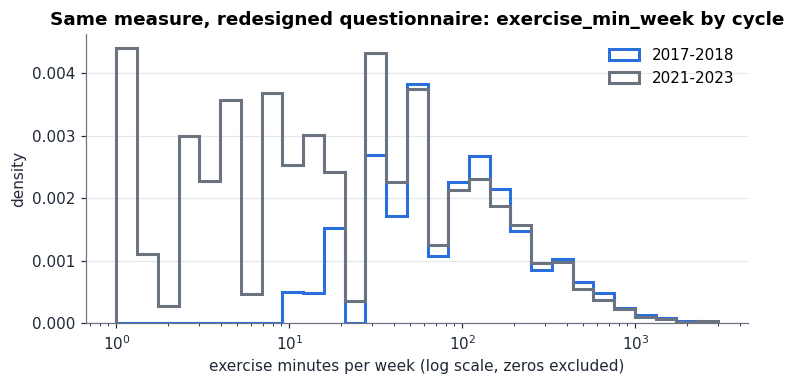

In [9]:
if len(tables) == 2:
    both = pd.DataFrame({c: t["exercise_min_week"].describe() for c, t in tables.items()}).round(1)
    both.loc["share >= 150 min (WHO)"] = [round((t["exercise_min_week"].dropna() >= 150).mean() * 100, 1) for t in tables.values()]
    both.loc["share == 0"] = [round((t["exercise_min_week"].dropna() == 0).mean() * 100, 1) for t in tables.values()]
    display(both)
    fig, ax = plt.subplots(figsize=(7, 3.6))
    bins = np.logspace(0, np.log10(L.CAP_MIN_WEEK), 30)
    for c, colour in zip(tables, [BLUE, MUTED]):
        v = tables[c]["exercise_min_week"].dropna()
        ax.hist(v[v > 0], bins=bins, histtype="step", linewidth=2, color=colour, label=c, density=True)
    ax.set_xscale("log"); ax.set_xlabel("exercise minutes per week (log scale, zeros excluded)"); ax.set_ylabel("density")
    ax.set_title("Same measure, redesigned questionnaire: exercise_min_week by cycle"); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(FIG / "p3_exercise_cycle_compare.png"); plt.show()

**What changed between cycles (write after looking at the table above):** ...

## 6. EDA for awareness stories

Each chart: risk rate of `cardiometabolic` (% with the condition) by a lifestyle group. The dashed line is the overall rate.
Saved to `reports/figures/p3_*.png`.

In [10]:
def load_with_target(cycle="2017-2018"):
    life = pd.read_csv(L.INTERIM_DIR / f"lifestyle_{cycle}.csv")
    for name in (f"merged_{cycle}.csv", f"people_{cycle}.csv"):
        path = L.INTERIM_DIR / name
        if path.exists():
            target = pd.read_csv(path, usecols=["seqn", "cardiometabolic"])
            df = life.merge(target, on="seqn", how="inner").dropna(subset=["cardiometabolic"])
            print(f"{len(df):,} adults with a known target (from {name}); overall rate {df.cardiometabolic.mean():.1%}")
            return df
    raise FileNotFoundError("need merged_<cycle>.csv or people_<cycle>.csv in data/interim")

def risk_bar(df, group, title, fname, xlabel):
    g = df.dropna(subset=[group]).groupby(group, observed=True)["cardiometabolic"].agg(["mean", "size"])
    g["pct"] = g["mean"] * 100
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    bars = ax.bar(g.index.astype(str), g["pct"], color=BLUE, width=0.55)
    for bar, (pct, n) in zip(bars, zip(g["pct"], g["size"])):
        ax.text(bar.get_x() + bar.get_width() / 2, pct + 0.4, f"{pct:.1f}%", ha="center", color=INK, fontsize=10)
        ax.text(bar.get_x() + bar.get_width() / 2, 0.4, f"n={n:,}", ha="center", color="white", fontsize=8)
    ax.axhline(df["cardiometabolic"].mean() * 100, color=MUTED, linestyle="--", linewidth=1)
    ax.set_ylabel("% with cardiometabolic condition"); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.set_ylim(0, max(g["pct"].max() * 1.2, 5))
    fig.tight_layout(); fig.savefig(FIG / fname); plt.show()
    return g

eda = load_with_target("2017-2018")

5,536 adults with a known target (from merged_2017-2018.csv); overall rate 26.1%


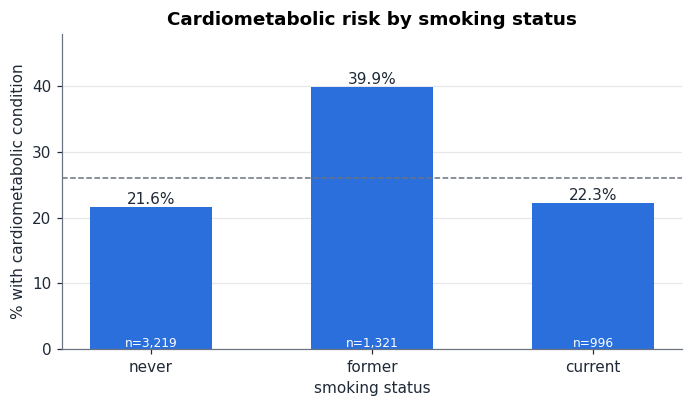

,mean,size,pct
smoking_status,,,
never,0.215906,3219,21.590556
former,0.398940,1321,39.894020
current,0.222892,996,22.289157


In [11]:
order = pd.CategoricalDtype(["never", "former", "current"], ordered=True)
eda["smoking_status"] = eda["smoking_status"].astype(order)
risk_bar(eda, "smoking_status", "Cardiometabolic risk by smoking status", "p3_risk_by_smoking.png", "smoking status")

**Finding 1:** ...

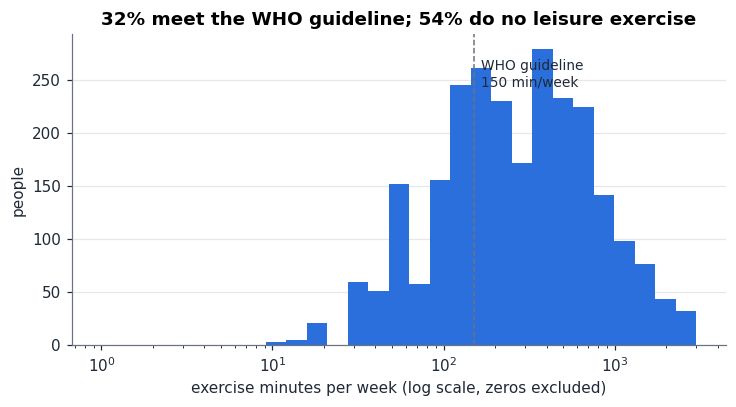

In [12]:
v = eda["exercise_min_week"].dropna()
share_who, share_zero = (v >= 150).mean() * 100, (v == 0).mean() * 100
fig, ax = plt.subplots(figsize=(6.8, 3.8))
ax.hist(v[v > 0], bins=np.logspace(0, np.log10(L.CAP_MIN_WEEK), 30), color=BLUE)
ax.set_xscale("log"); ax.axvline(150, color=MUTED, linestyle="--", linewidth=1)
ax.text(165, ax.get_ylim()[1] * 0.92, "WHO guideline\n150 min/week", color=INK, fontsize=9, va="top")
ax.set_xlabel("exercise minutes per week (log scale, zeros excluded)"); ax.set_ylabel("people")
ax.set_title(f"{share_who:.0f}% meet the WHO guideline; {share_zero:.0f}% do no leisure exercise")
fig.tight_layout(); fig.savefig(FIG / "p3_exercise_distribution.png"); plt.show()

**Finding 2:** ...

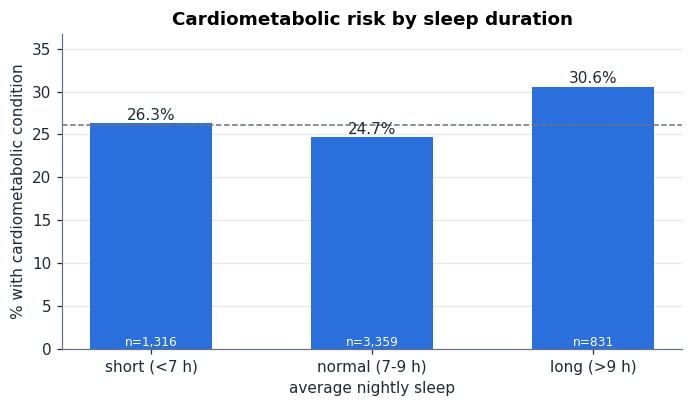

,mean,size,pct
sleep_group,,,
short (<7 h),0.262918,1316,26.291793
normal (7-9 h),0.247097,3359,24.709735
long (>9 h),0.305656,831,30.565584


In [13]:
eda["sleep_group"] = pd.cut(eda["sleep_hours"], [0, 7, 9.01, 24], right=False, labels=["short (<7 h)", "normal (7-9 h)", "long (>9 h)"])
risk_bar(eda, "sleep_group", "Cardiometabolic risk by sleep duration", "p3_risk_by_sleep.png", "average nightly sleep")

**Finding 3:** ...

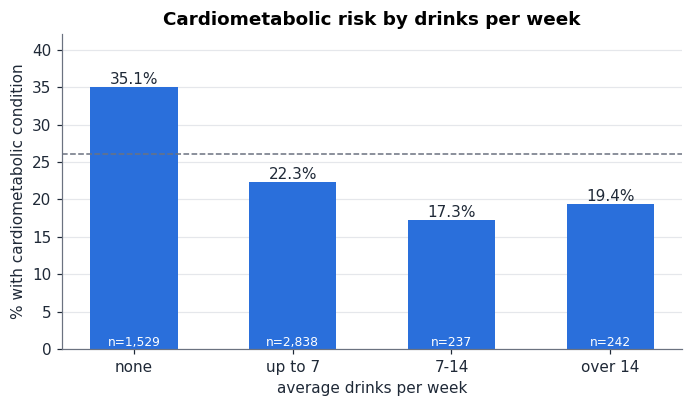

,mean,size,pct
drinks_group,,,
none,0.350556,1529,35.055592
up to 7,0.222692,2838,22.269204
7-14,0.172996,237,17.299578
over 14,0.194215,242,19.421488


In [14]:
eda["drinks_group"] = pd.cut(eda["alcohol_drinks_week"], [-0.01, 0, 7, 14, 1000], labels=["none", "up to 7", "7-14", "over 14"])
risk_bar(eda, "drinks_group", "Cardiometabolic risk by drinks per week", "p3_risk_by_alcohol.png", "average drinks per week")

**Finding 4:** ...

Caution to say out loud: risk differences are not causal (age and other factors are not controlled here), and
`diet_quality` is for EDA and app tips only - it is empty in 2021-2023, so it cannot be a model feature.